# Predicting long term movie performance using as few early reviews

## Data Cleaning

In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

### Cleaning Movie and Review Data

- Load Horror, Animation, and Adventure movie tables and label each row with its source genre
- Resolve cross-genre duplicates so each movie keeps one preferred genre
- Parse runtime into minutes; clean MPAA rating, release year, and IMDb rating
- Assign an id for each movie
- Load matching review CSVs, drop reviews without a star rating or date
- Clean HTML from review text, order reviews by date within each movie
- Label movies positive if star rating ≥ 7

In [2]:
# load one CSV per genre and tag rows with that genre
movie_frames = []
for genre in ["Horror", "Animation", "Adventure"]:
    df = pd.read_csv(Path("movies_per_genre") / f"{genre}.csv")
    df["genre"] = genre
    movie_frames.append(df)

movies = pd.concat(movie_frames, ignore_index=True)

# prefer the first matching genre that appears if the title appears in more than one genre
def preferred_genre(row):
    tags = [t.strip() for t in str(row["genres"]).split(";") if t.strip()]
    for tag in tags:
        if tag in ["Horror", "Animation", "Adventure"]:
            return tag
    return row["genre"]

movies["genre"] = movies.apply(preferred_genre, axis=1)
movies = movies.drop_duplicates(subset=["name", "year"], keep="first").reset_index(drop=True)
movies.head()

,name,year,movie_rated,run_length,genres,release_date,rating,num_raters,num_reviews,review_url,genre
0,The Shining,1980,R,2h 26min,Drama; Horror;,13 June 1980 (USA),8.4,860290,1805,https://www.imdb.com/title/tt0081505/reviews/_...,Horror
1,Alien,1979,R,1h 57min,Horror; Sci-Fi;,22 June 1979 (USA),8.4,762793,1423,https://www.imdb.com/title/tt0078748/reviews/_...,Horror
2,World War Z,2013,PG-13,1h 56min,Action; Adventure; Horror;,21 June 2013 (USA),7.0,586801,1125,https://www.imdb.com/title/tt0816711/reviews/_...,Adventure
3,Psycho,1960,R,1h 49min,Horror; Mystery; Thriller;,8 September 1960 (USA),8.5,580951,1263,https://www.imdb.com/title/tt0054215/reviews/_...,Horror
4,Shaun of the Dead,2004,R,1h 39min,Comedy; Horror;,24 September 2004 (USA),7.9,499244,971,https://www.imdb.com/title/tt0365748/reviews/_...,Horror


In [3]:
# convert strings like into total minutes
def parse_runtime_minutes(value):
    if pd.isna(value):
        return np.nan
    text = str(value).strip().lower()
    hours = re.search(r"(\d+)\s*h", text)
    minutes = re.search(r"(\d+)\s*min", text)
    total = 0
    if hours:
        total += int(hours.group(1)) * 60
    if minutes:
        total += int(minutes.group(1))
    return total if total > 0 else np.nan


# clean and rename metadata columns
movies["movie_id"] = np.arange(len(movies), dtype=int)
movies["runtime"] = movies["run_length"].map(parse_runtime_minutes)
movies["mpaa_rating"] = movies["movie_rated"].astype(str).str.strip()
movies["release_year"] = movies["year"].astype(int)
movies["imdb_rating"] = movies["rating"].astype(float)
movies["num_raters"] = movies["num_raters"].astype(int)
movies["num_reviews_listed"] = movies["num_reviews"].astype(int)

movies.head()

,name,year,movie_rated,run_length,genres,release_date,rating,num_raters,num_reviews,review_url,genre,movie_id,runtime,mpaa_rating,release_year,imdb_rating,num_reviews_listed
0,The Shining,1980,R,2h 26min,Drama; Horror;,13 June 1980 (USA),8.4,860290,1805,https://www.imdb.com/title/tt0081505/reviews/_...,Horror,0,146,R,1980,8.4,1805
1,Alien,1979,R,1h 57min,Horror; Sci-Fi;,22 June 1979 (USA),8.4,762793,1423,https://www.imdb.com/title/tt0078748/reviews/_...,Horror,1,117,R,1979,8.4,1423
2,World War Z,2013,PG-13,1h 56min,Action; Adventure; Horror;,21 June 2013 (USA),7.0,586801,1125,https://www.imdb.com/title/tt0816711/reviews/_...,Adventure,2,116,PG-13,2013,7.0,1125
3,Psycho,1960,R,1h 49min,Horror; Mystery; Thriller;,8 September 1960 (USA),8.5,580951,1263,https://www.imdb.com/title/tt0054215/reviews/_...,Horror,3,109,R,1960,8.5,1263
4,Shaun of the Dead,2004,R,1h 39min,Comedy; Horror;,24 September 2004 (USA),7.9,499244,971,https://www.imdb.com/title/tt0365748/reviews/_...,Horror,4,99,R,2004,7.9,971


In [4]:
# review filenames replace ':' with '_' in the movie title
# so we change it so that we can find the matching csv file
def review_filename(name, year):
    return f"{str(name).replace(':', '_')} {int(year)}.csv"


# clean review text: strip HTML tags and collapse whitespace
def clean_review_text(text):
    if pd.isna(text):
        return ""
    cleaned = re.sub(r"<br\s*/?>", " ", str(text), flags=re.IGNORECASE)
    cleaned = re.sub(r"<[^>]+>", " ", cleaned)
    cleaned = re.sub(r"\s+", " ", cleaned).strip()
    return cleaned


# load each movie's review file and attach movie_id / genre
review_frames = []
for row in movies.itertuples(index=False):
    path = Path("all_reviews_per_movie_raw") / review_filename(row.name, row.release_year)
    if not path.exists():
        continue
    rev = pd.read_csv(path)
    rev["movie_id"] = row.movie_id
    rev["genre"] = row.genre
    review_frames.append(rev)

reviews = pd.concat(review_frames, ignore_index=True)

# drop reviews with missing star rating or date
reviews["star_rating"] = pd.to_numeric(reviews["rating"], errors="coerce")
reviews = reviews.dropna(subset=["star_rating"]).copy()
reviews["star_rating"] = reviews["star_rating"].astype(int)

reviews["date"] = pd.to_datetime(reviews["date"], errors="coerce")
reviews = reviews.dropna(subset=["date"]).copy()

# clean text and create binary positive label
reviews["text"] = reviews["review"].map(clean_review_text)
reviews = reviews[reviews["text"].str.len() > 0].copy()
reviews["positive"] = (reviews["star_rating"] >= 7).astype(int)

# chronological order within each movie (1 = first review)
reviews = reviews.sort_values(["movie_id", "date", "username"], kind="mergesort")
reviews["review_order"] = reviews.groupby("movie_id").cumcount() + 1

reviews = reviews[
    ["movie_id", "genre", "review_order", "date", "star_rating", "positive", "text"]
].reset_index(drop=True)

# keep only movies that still have at least one usable review
movies = movies[movies["movie_id"].isin(reviews["movie_id"].unique())].reset_index(drop=True)
reviews.head()

,movie_id,genre,review_order,date,star_rating,positive,text
0,0,Horror,1,1998-08-04,10,1,"First of all, I loved the book. It remains my ..."
1,0,Horror,2,1998-08-07,10,1,Although it is sometimes considered to be a mo...
2,0,Horror,3,1998-09-07,10,1,"Stanley Kubrick's ""The Shining"" was a high-wat..."
3,0,Horror,4,1998-10-11,10,1,This is a remarkable milestone in cinema. Kubr...
4,0,Horror,5,1998-10-14,10,1,What can I say to all the fans of the novel Th...


In [5]:
# There are movies in which their 1st review is much later than the US release date
# Drop movies released before the very first review (1998) in the dataset
first_review_year = reviews.date.min().year
# Drop movies released within 5 years of the last reviews (2020) 
last_review_year = reviews.date.max().year

print(f"Before drop:\n {(movies.groupby("genre")["movie_id"].nunique())}")

# Keeping movies that came out in or after 1998 until 2015
movies = movies[movies["year"].between(first_review_year, last_review_year)].reset_index(drop=True)

print(f"After drop:\n {(movies.groupby("genre")["movie_id"].nunique())}")

# keep only reviews that are in movies 
reviews = reviews[reviews["movie_id"].isin(movies["movie_id"].unique())].reset_index(drop=True)
reviews.head()

Before drop:
 genre
Adventure     90
Animation    100
Horror        94
Name: movie_id, dtype: int64
After drop:
 genre
Adventure    79
Animation    80
Horror       71
Name: movie_id, dtype: int64


,movie_id,genre,review_order,date,star_rating,positive,text
0,2,Adventure,1,2013-06-09,1,0,SPOILER ALERT. SPOILER ALERT! You have been wa...
1,2,Adventure,2,2013-06-10,9,1,"World War Z, while based off the Max Brooks no..."
2,2,Adventure,3,2013-06-16,10,1,I really didn't want to have high expectations...
3,2,Adventure,4,2013-06-16,10,1,I just got back from viewing a special screeni...
4,2,Adventure,5,2013-06-17,1,0,Highly disappointed. Don't read any other high...


### Train/Validation/Test Split

- Split by movie 
- Stratify on genre: 70% train, then split the remaining 30% into 15% validation / 15% test
- Split train movies in half into `lstm_train` and `mlp_train`
- Add a `split` column on movies and merge it onto reviews by `movie_id`

In [6]:
# 70/30 split stratified by genre
train_movies, temp_movies = train_test_split(
    movies, test_size=0.30, stratify=movies["genre"], random_state=42)

# split 30% in half (15% validation, 15% test)
val_movies, test_movies = train_test_split(
    temp_movies, test_size=0.50, stratify=temp_movies["genre"], random_state=42)

# split train in half: one half for LSTM and the other half for MLP
lstm_train_movies, mlp_train_movies = train_test_split(
    train_movies, test_size=0.50, stratify=train_movies["genre"], random_state=42)

# create column identifying which split each movie belongs to
movies = movies.copy()
movies["split"] = None
for subset, label in [
    (lstm_train_movies, "lstm_train"),
    (mlp_train_movies, "mlp_train"),
    (val_movies, "validation"),
    (test_movies, "test"),
]:
    movies.loc[movies["movie_id"].isin(subset["movie_id"]), "split"] = label

# copy each movie's split label to every review that has the same movie_id
reviews = reviews.merge(movies[["movie_id", "split"]], on="movie_id", how="left")

In [7]:
# to see the number of movies and reviews in each split by genre 
# movies.groupby(["split", "genre"]).size().unstack(fill_value=0)
# reviews.groupby(["split", "genre"]).size().unstack(fill_value=0)

### Movie Metadata DataFrame

- Set different values of k (number of earliest reviews)
- For each k value, keep movies with at least k reviews
- Build one row per (movie, k) pair with split, numeric metadata, and IMDb rating as the target
- One-hot encode genre and MPAA rating so MLP features are numeric
- Save `movies_clean.csv` and `reviews_clean.csv`

In [7]:
# create a column with the number of reviews per movie
n_reviews = reviews.groupby("movie_id").size().rename("n_reviews")

# merge the number of reviews with the movies dataframe
movies_with_counts = movies.merge(n_reviews, on="movie_id", how="left")

# Monthly time windows based off the date of the first review of a movie 
k_values = [0, 1, 3, 6, 12, "midpoint"]
reviews["first_review_date"] = (reviews.groupby("movie_id")["date"].transform("min"))
reviews["months_since_first_review"] = ((reviews["date"].dt.year - reviews["first_review_date"].dt.year) * 12 
                                             + (reviews["date"].dt.month - reviews["first_review_date"].dt.month))
meta_cols = [
    "movie_id", 
    "split", 
    "genre", 
    "runtime", 
    "mpaa_rating",
    "release_year", 
    "imdb_rating", 
    "num_raters", 
    "num_reviews_listed",]

mlp_base = movies_with_counts[meta_cols].copy()

# one-hot encode categorical
# Leave split as a string for filtering
mlp_base = pd.get_dummies(mlp_base, columns=["genre", "mpaa_rating"], dtype=int)
mlp_base = mlp_base.sort_values("movie_id").reset_index(drop=True)

mlp_base

,movie_id,split,runtime,release_year,imdb_rating,num_raters,num_reviews_listed,genre_Adventure,genre_Animation,genre_Horror,mpaa_rating_G,mpaa_rating_Not Rated,mpaa_rating_PG,mpaa_rating_PG-13,mpaa_rating_R,mpaa_rating_TV-MA
0,2,lstm_train,116,2013,7.0,586801,1125,1,0,0,0,0,0,1,0,0
1,4,test,99,2004,7.9,499244,971,0,0,1,0,0,0,0,1,0
2,5,mlp_train,104,2017,7.7,465577,1566,0,0,1,0,0,0,0,1,0
3,6,validation,135,2017,7.3,437678,1914,0,0,1,0,0,0,0,1,0
4,7,lstm_train,112,2013,7.5,427067,1054,0,0,1,0,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
225,278,test,161,2002,7.4,531256,930,1,0,0,0,0,1,0,0,0
226,279,lstm_train,141,2017,7.4,531221,2179,1,0,0,0,0,0,1,0,0
227,280,validation,127,2004,7.3,529344,1450,1,0,0,0,0,0,1,0,0
228,281,mlp_train,142,2004,7.9,528503,1592,1,0,0,0,0,1,0,0,0


In [8]:
# save copy of clean movie and review data for model use
clean_dir = Path("data/clean")
clean_dir.mkdir(parents=True, exist_ok=True)

movies.to_csv(clean_dir / "movies_clean.csv", index=False)
reviews[
    ["movie_id", "genre", "split", "review_order", "date", "star_rating", "positive", "text", "first_review_date", "months_since_first_review"]
].to_csv(clean_dir / "reviews_clean.csv", index=False)

## What do the early star ratings alone tell us, and how sure can we be? (Bayesian)

In [9]:
import pandas as pd
import numpy as np
from scipy.stats import beta

In [10]:
# Read the data and take the necessary columns for model 
# Review data
reviews = pd.read_csv("data/clean/reviews_clean.csv")
reviews_nec = reviews[['movie_id', 'genre', 'review_order', 'date','positive', 'first_review_date', 'months_since_first_review']]

# Movie data 
movies = pd.read_csv("data/clean/movies_clean.csv")
movies["release_date"] = movies["release_date"].str.split("(").str[0].str.strip()
movies["release_date"] = pd.to_datetime(movies["release_date"])
movies_nec = movies[["name", "release_date", "movie_id","num_reviews_listed"]]

# Merge dataframe where each row is a review 
merged = reviews_nec.merge(movies_nec, on="movie_id")
merged.head()

,movie_id,genre,review_order,date,positive,first_review_date,months_since_first_review,name,release_date,num_reviews_listed
0,2,Adventure,1,2013-06-09,0,2013-06-09,0,World War Z,2013-06-21,1125
1,2,Adventure,2,2013-06-10,1,2013-06-09,0,World War Z,2013-06-21,1125
2,2,Adventure,3,2013-06-16,1,2013-06-09,0,World War Z,2013-06-21,1125
3,2,Adventure,4,2013-06-16,1,2013-06-09,0,World War Z,2013-06-21,1125
4,2,Adventure,5,2013-06-17,0,2013-06-09,0,World War Z,2013-06-21,1125


In [11]:
# Calculate prior means and prior belief of alpha and beta for each genre
genre_stats = {}
prior_var = 0.01  # maybe should do parameter testing??

for genre in merged["genre"].unique():
    genre_data = merged[merged["genre"] == genre]
    pos_count = genre_data["positive"].sum()
    total_count = len(genre_data)
    prior_mean = pos_count / total_count    # prior mean is the genre approval rate
    
    # prior strength (n)
    n = (prior_mean * (1 - prior_mean) / prior_var) - 1
    alpha = prior_mean * n 
    beta = (1 - prior_mean) * n 
    
    genre_stats[genre] = {"prior_mean": prior_mean,
                          "alpha" : alpha,
                          "beta" : beta }
print(genre_stats)

{'Adventure': {'prior_mean': np.float64(0.6562445155454754), 'alpha': np.float64(14.147821382561608), 'beta': np.float64(7.410943753634362)}, 'Horror': {'prior_mean': np.float64(0.5387634361362504), 'alpha': np.float64(12.849367658869648), 'beta': np.float64(11.000371943021433)}, 'Animation': {'prior_mean': np.float64(0.7518377314295681), 'alpha': np.float64(13.27578202651603), 'beta': np.float64(4.381993676324844)}}


In [12]:
# See how posterior mean gets updated as we add more reviews until the last movie's review
results = []

for genre, stats in genre_stats.items():
    # Prior belief 
    alpha_0 = stats["alpha"]
    beta_0 = stats["beta"]
    
    # Movies in genre
    genre_movies = merged[merged["genre"] == genre]
    
    for movie_id in genre_movies["movie_id"].unique():
        # Reviews for a movie
        reviews_per_movie = genre_movies[genre_movies["movie_id"] == movie_id]

        # Labeling prior with k = -1 
        results.append({"genre": genre,"movie_id": movie_id, "k": -1, "alpha": alpha_0, "beta": beta_0, "posterior_mean": stats["prior_mean"]})
        
        # Time windows are within the month of the first review, 1 month/3 months/6 months/1 year after, and the midpoint of the movie's
        # review period, which is until 2020 (ex: if it released in 2015, the midpoint would be 2018)
        time_windows = [0, 1, 3, 6, 12, "midpoint"]
        for k in time_windows:
            if k == "midpoint":
                midpoint = reviews_per_movie["months_since_first_review"].max() // 2
                early_reviews = reviews_per_movie[reviews_per_movie["months_since_first_review"] <= midpoint]
            else:
                early_reviews =  reviews_per_movie[reviews_per_movie["months_since_first_review"] <= k]
            
            # Count positive and negative reviews
            positive_count = early_reviews["positive"].sum()
            negative_count = len(early_reviews) - positive_count

            # Update alpha and beta
            alpha_k = alpha_0 + positive_count
            beta_k = beta_0 + negative_count

            # Calculate posterior mean
            posterior_mean = alpha_k / (alpha_k + beta_k)

            results.append({"genre": genre,"movie_id": movie_id, "k": k, "alpha": alpha_k, "beta": beta_k, "posterior_mean": posterior_mean})

In [13]:
results_df = pd.DataFrame(results)

# Compare posterior mean to movie's actual approval rate 
movie_approvals = {}
for movie in merged["movie_id"].unique():
    movie_data = merged[merged["movie_id"] == movie]
    pos_count = movie_data["positive"].sum()
    total_count = len(movie_data)
    approval = pos_count / total_count
    
    movie_approvals[movie] = approval

results_df["actual_approval"] = results_df["movie_id"].map(movie_approvals)
results_df["prediction_error"] = results_df["posterior_mean"] - results_df["actual_approval"]
results_df["posterior_std"] = np.sqrt((results_df["alpha"] * results_df["beta"]) /
    ((results_df["alpha"] + results_df["beta"])**2 *(results_df["alpha"] + results_df["beta"] + 1)))
results_df[["genre", "movie_id", "k", "posterior_mean", "actual_approval", "prediction_error", "posterior_std"]].head(7)

,genre,movie_id,k,posterior_mean,actual_approval,prediction_error,posterior_std
0,Adventure,2,-1,0.656245,0.529899,0.126346,0.100000
1,Adventure,2,0,0.580128,0.529899,0.050229,0.026666
2,Adventure,2,1,0.548392,0.529899,0.018493,0.021504
3,Adventure,2,3,0.531631,0.529899,0.001732,0.019184
4,Adventure,2,6,0.525718,0.529899,-0.004181,0.017953
5,Adventure,2,12,0.518349,0.529899,-0.011550,0.017255
6,Adventure,2,midpoint,0.515741,0.529899,-0.014158,0.016252


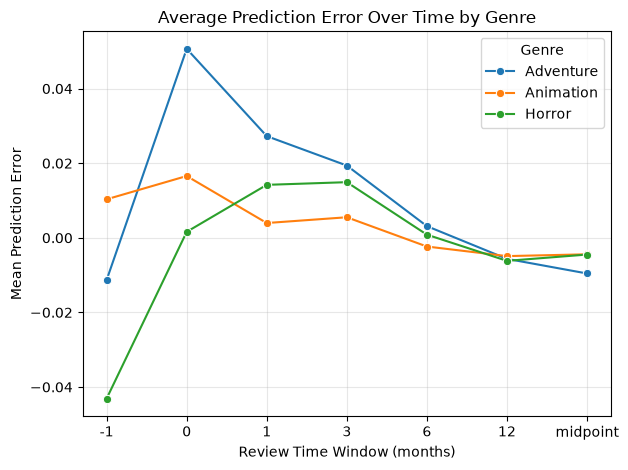

In [14]:
import seaborn as sns
import matplotlib.pyplot as plt
avg_genre_error = (results_df.groupby(["genre", "k"])["prediction_error"].mean().reset_index())

avg_genre_error["k"] = avg_genre_error["k"].astype(str)

sns.lineplot(data=avg_genre_error, x="k", y="prediction_error", hue="genre", marker="o")

plt.xlabel("Review Time Window (months)")
plt.ylabel("Mean Prediction Error")
plt.title("Average Prediction Error Over Time by Genre")
plt.legend(title="Genre")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

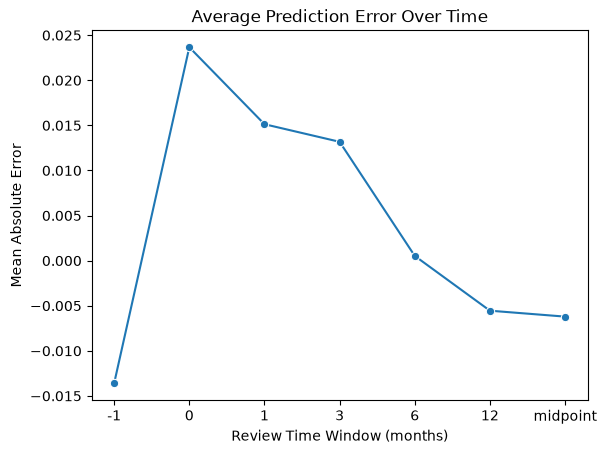

In [15]:
avg_error = (results_df.groupby("k")["prediction_error"].mean().reset_index())
avg_error["k"] = avg_error["k"].astype(str)
sns.lineplot(data=avg_error, x="k", y="prediction_error",marker="o")

plt.xlabel("Review Time Window (months)")
plt.ylabel("Mean Absolute Error")
plt.title("Average Prediction Error Over Time")
plt.show()

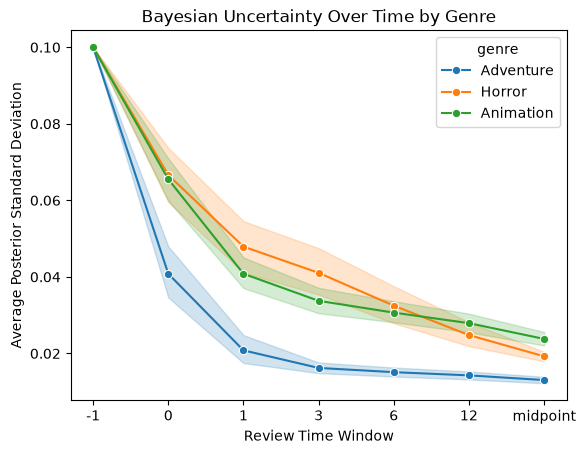

In [16]:
plot_df = results_df.copy()
plot_df["k"] = plot_df["k"].astype(str)
sns.lineplot(
    data=plot_df,
    x="k",
    y="posterior_std",
    hue="genre",
    marker="o"
)

plt.xlabel("Review Time Window")
plt.ylabel("Average Posterior Standard Deviation")
plt.title("Bayesian Uncertainty Over Time by Genre")
plt.show()

In [17]:
results_df["absolute_error"] = results_df["prediction_error"].abs()

results_df["squared_error"] = results_df["prediction_error"]** 2

bayes_metrics = results_df.groupby("k").agg(MAE=("absolute_error", "mean"), RMSE=("squared_error", lambda x: np.sqrt(x.mean()))).reset_index()
print(bayes_metrics)

          k       MAE      RMSE
0        -1  0.118732  0.145739
1         0  0.083178  0.106703
2         1  0.052318  0.074618
3         3  0.038656  0.059560
4         6  0.027853  0.043282
5        12  0.022268  0.034141
6  midpoint  0.014396  0.018952


In [18]:
posterior_results = results_df[["genre", "movie_id", "k", "posterior_mean", "posterior_std"]]
mlp_base = posterior_results.merge(mlp_base, on="movie_id", how="left")
mlp_base.head()

,genre,movie_id,k,posterior_mean,posterior_std,split,runtime,release_year,imdb_rating,num_raters,num_reviews_listed,genre_Adventure,genre_Animation,genre_Horror,mpaa_rating_G,mpaa_rating_Not Rated,mpaa_rating_PG,mpaa_rating_PG-13,mpaa_rating_R,mpaa_rating_TV-MA
0,Adventure,2,-1,0.656245,0.100000,lstm_train,116,2013,7.0,586801,1125,1,0,0,0,0,0,1,0,0
1,Adventure,2,0,0.580128,0.026666,lstm_train,116,2013,7.0,586801,1125,1,0,0,0,0,0,1,0,0
2,Adventure,2,1,0.548392,0.021504,lstm_train,116,2013,7.0,586801,1125,1,0,0,0,0,0,1,0,0
3,Adventure,2,3,0.531631,0.019184,lstm_train,116,2013,7.0,586801,1125,1,0,0,0,0,0,1,0,0
4,Adventure,2,6,0.525718,0.017953,lstm_train,116,2013,7.0,586801,1125,1,0,0,0,0,0,1,0,0


## Does review data add anything? (LSTM)

In [19]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.metrics import accuracy_score, precision_score, recall_score, roc_auc_score, roc_curve
from sklearn.model_selection import train_test_split

### Data Set Up

- Load the cleaned movies and reviews
- LSTM validation set taken from `lstm_train` for early stopping


In [20]:
# set random seed
np.random.seed(42)
tf.random.set_seed(42)

movies = pd.read_csv(Path("data/clean") / "movies_clean.csv")
reviews = pd.read_csv(Path("data/clean") / "reviews_clean.csv")
reviews["date"] = pd.to_datetime(reviews["date"])
# replace any missing review text with ""
reviews["text"] = reviews["text"].fillna("")

# take a 15% holdout from lstm_train movies only for early stopping
lstm_movies = movies[movies["split"] == "lstm_train"]
lstm_fit_movies, lstm_val_movies = train_test_split(
    lstm_movies,
    test_size=0.15,
    stratify=lstm_movies["genre"],
    random_state=42,
)
# label movies for lstm fit/val only on movies in lstm train, everything else is empty
movies["lstm_split"] = None
movies.loc[movies["movie_id"].isin(lstm_fit_movies["movie_id"]), "lstm_split"] = "lstm_fit"
movies.loc[movies["movie_id"].isin(lstm_val_movies["movie_id"]), "lstm_split"] = "lstm_val"

# copy the holdout label onto reviews without changing the shared split column
reviews = reviews.merge(movies[["movie_id", "lstm_split"]], on="movie_id", how="left")

print("lstm_fit movies:", (movies["lstm_split"] == "lstm_fit").sum())
print("lstm_val movies:", (movies["lstm_split"] == "lstm_val").sum())
print("lstm_fit reviews:", (reviews["lstm_split"] == "lstm_fit").sum())
print("lstm_val reviews:", (reviews["lstm_split"] == "lstm_val").sum())


lstm_fit movies: 68
lstm_val movies: 12
lstm_fit reviews: 78330
lstm_val reviews: 13077


### Class and Movie Review Balance

- Training and evaluation use only reviews that have a star rating
- Check the fraction of positive reviews overall
- Create class weights for imbalanced (under 40%) positive and negative classes in training set
- Check how many labeled reviews each movie has in training set
- Weight each training set review by 1 over that movie's review count, times its class weight, so long movies do not dominate and no reviews are dropped


In [21]:
# make sure training and evaluation have a star rating / positive label
labeled = reviews[reviews["positive"].notna()]
fit_reviews = labeled[labeled["lstm_split"] == "lstm_fit"]
val_reviews = labeled[labeled["lstm_split"] == "lstm_val"]
test_reviews = labeled[labeled["split"] == "test"]

n_total = len(fit_reviews)
n_pos = int((fit_reviews["positive"] == 1).sum())
n_neg = int((fit_reviews["positive"] == 0).sum())
minority_fraction = min(n_pos, n_neg) / n_total

# up-weight the smaller class so it contributes about as much as the larger one
if minority_fraction < 0.40:
    class_weights = {
        0: n_total / (2 * n_neg),
        1: n_total / (2 * n_pos),
    }
    print("class weights:", class_weights)
else:
    class_weights = None


class weights: {0: 1.3741623100943827, 1: 0.7859880792309699}


In [22]:
# how many labeled reviews each lstm_fit movie has
review_counts = fit_reviews.groupby("movie_id").size()

print("min:", review_counts.min())
print("median:", review_counts.median())
print("mean:", review_counts.mean())
print("max:", review_counts.max())

# each movie gets the same total weight, so a long movie does not dominate training
movie_weight = 1 / review_counts
sample_weight = fit_reviews["movie_id"].map(movie_weight)

# multiply by the class weight so the smaller class still counts about as much
if class_weights is not None:
    label_weight = fit_reviews["positive"].map(class_weights)
    sample_weight = sample_weight * label_weight

# average weight of 1 keeps the loss on the usual scale
sample_weight = sample_weight / sample_weight.mean()
sample_weight = sample_weight.to_numpy()


min: 197
median: 731.0
mean: 1151.9117647058824
max: 8626


### Text Preprocessing and Tokenization

- Count words in reviews and set the sequence length to the 90th percentile
- Longer reviews are cut off and shorter ones are padded with zeros
- Fit the word vocabulary on train text only, so validation and test words do not leak in
- Turn the LSTM fit, validation, and test reviews into integer sequences


In [23]:
# word count = number of whitespace separated words
word_counts = fit_reviews["text"].astype(str).str.split().str.len()

print("min:", word_counts.min())
print("median:", word_counts.median())
print("mean:", word_counts.mean())
print("max:", word_counts.max())

# how many words the LSTM reads from each review 
sequence_length = int(round(word_counts.quantile(0.90)))
print("sequence length:", sequence_length)

# turn every review into a fixed-length list of integers
vectorizer = tf.keras.layers.TextVectorization(
    max_tokens=20000,
    standardize="lower_and_strip_punctuation",
    output_mode="int",
    output_sequence_length=sequence_length,
)
vectorizer.adapt(fit_reviews["text"].to_numpy())

# train on every lstm_fit review
# sample_weight is in this same row order
X_fit = vectorizer(fit_reviews["text"].to_numpy())
y_fit = fit_reviews["positive"].to_numpy()
X_val = vectorizer(val_reviews["text"].to_numpy())
y_val = val_reviews["positive"].to_numpy()
X_test = vectorizer(test_reviews["text"].to_numpy())
y_test = test_reviews["positive"].to_numpy()


min: 1
median: 170.0
mean: 242.9810289799566
max: 2753
sequence length: 545


### Build the LSTM

- The embedding turns each word id into 100 learned numbers and skips the padding zeros
- The LSTM reads the review one word at a time and outputs one summary vector
- Dropout randomly drops 30% of those numbers during training to reduce overfitting
- The last layer outputs the probability that the review is positive


In [24]:
# set seed again
tf.random.set_seed(42)
np.random.seed(42)

model = tf.keras.Sequential([
    tf.keras.layers.Embedding(input_dim=20000, output_dim=100, mask_zero=True),
    tf.keras.layers.LSTM(64),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(1, activation="sigmoid"),
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy", tf.keras.metrics.AUC(name="auc")],
)

# summary needs a fixed sequence length before the model has been trained
model.build(input_shape=(None, X_fit.shape[1]))
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 545, 100)       │     2,000,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        42,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,042,305 (7.79 MB)

 Trainable params: 2,042,305 (7.79 MB)

 Non-trainable params: 0 (0.00 B)

### Train the LSTM

- Train on every `lstm_fit` review, using the sample weights, and watch loss on `lstm_val`
- Stop if validation loss does not improve for 2 epochs, and keep the best weights
- Plot training and validation loss, then accuracy
- Save the trained model


Epoch 1/10
1224/1224 ━━━━━━━━━━━━━━━━━━━━ 234s 191ms/step - accuracy: 0.7604 - auc: 0.8366 - loss: 0.5064 - val_accuracy: 0.7978 - val_auc: 0.8675 - val_loss: 0.4467
Epoch 2/10
1224/1224 ━━━━━━━━━━━━━━━━━━━━ 230s 188ms/step - accuracy: 0.8172 - auc: 0.8843 - loss: 0.4217 - val_accuracy: 0.8014 - val_auc: 0.8854 - val_loss: 0.4352
Epoch 3/10
1224/1224 ━━━━━━━━━━━━━━━━━━━━ 235s 192ms/step - accuracy: 0.8641 - auc: 0.9306 - loss: 0.3136 - val_accuracy: 0.8117 - val_auc: 0.8897 - val_loss: 0.4320
Epoch 4/10
1224/1224 ━━━━━━━━━━━━━━━━━━━━ 250s 204ms/step - accuracy: 0.8749 - auc: 0.9393 - loss: 0.2747 - val_accuracy: 0.8100 - val_auc: 0.8785 - val_loss: 0.4575
Epoch 5/10
1224/1224 ━━━━━━━━━━━━━━━━━━━━ 249s 204ms/step - accuracy: 0.8888 - auc: 0.9509 - loss: 0.2332 - val_accuracy: 0.8016 - val_auc: 0.8807 - val_loss: 0.4904


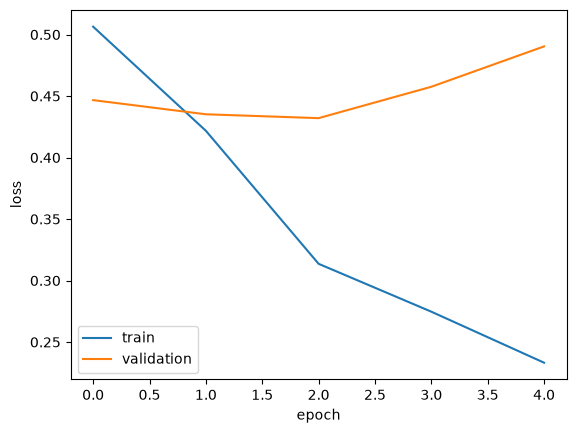

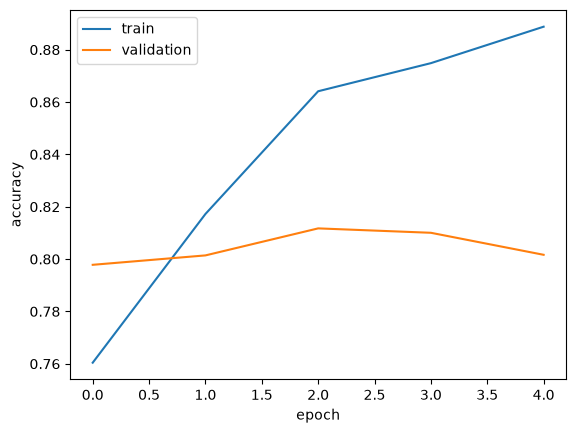

In [25]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True,
)

history = model.fit(
    X_fit,
    y_fit,
    validation_data=(X_val, y_val),
    batch_size=64,
    epochs=10,
    callbacks=[early_stopping],
    sample_weight=sample_weight,
)

# plot training and validation loss per epoch
plt.figure()
plt.plot(history.history["loss"], label="train")
plt.plot(history.history["val_loss"], label="validation")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.legend()
plt.show()

# plot accuracy per epoch
plt.figure()
plt.plot(history.history["accuracy"], label="train")
plt.plot(history.history["val_accuracy"], label="validation")
plt.xlabel("epoch")
plt.ylabel("accuracy")
plt.legend()
plt.show()

model_dir = Path("models")
model_dir.mkdir(parents=True, exist_ok=True)
model.save(model_dir / "lstm_sentiment.keras")


### Evaluate on Test Movies

- Score labeled test reviews
- Compare the LSTM with a majority-class baseline on accuracy, precision, recall, and AUC
- The baseline always predicts the most common label in training data, so its AUC is 0.5
- Plot the LSTM ROC curve

586/586 ━━━━━━━━━━━━━━━━━━━━ 39s 67ms/step


,accuracy,precision,recall,AUC
LSTM,0.832742,0.884634,0.849161,0.904807
Majority baseline,0.639417,0.639417,1.000000,0.500000


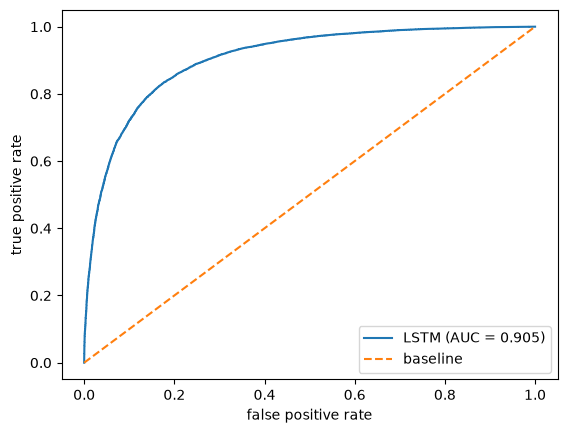

In [26]:
# function to score review predictions
def classification_metrics(y_true, y_pred, y_prob):
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, zero_division=0)
    recall = recall_score(y_true, y_pred, zero_division=0)
    # distinction for majority baseline vs review prediction
    if pd.Series(y_prob).nunique() < 2:
        auc = 0.5
    else:
        auc = roc_auc_score(y_true, y_prob)
    return accuracy, precision, recall, auc

# get test-set predictions and positive labels
y_prob = model.predict(X_test, batch_size=64).reshape(-1)
y_pred = (y_prob >= 0.5).astype(int)

# most common label in lstm_fit
if (fit_reviews["positive"] == 1).sum() >= (fit_reviews["positive"] == 0).sum():
    majority_label = 1
else:
    majority_label = 0

y_pred_majority = np.full(len(y_test), majority_label)
y_prob_majority = np.full(len(y_test), float(majority_label))

lstm_accuracy, lstm_precision, lstm_recall, lstm_auc = classification_metrics(y_test, y_pred, y_prob)
base_accuracy, base_precision, base_recall, base_auc = classification_metrics(y_test, y_pred_majority, y_prob_majority)

comparison = pd.DataFrame(
    {
        "accuracy": [lstm_accuracy, base_accuracy],
        "precision": [lstm_precision, base_precision],
        "recall": [lstm_recall, base_recall],
        "AUC": [lstm_auc, base_auc],
    },
    index=["LSTM", "Majority baseline"],
)
display(comparison)

fpr, tpr, thresholds = roc_curve(y_test, y_prob)
plt.figure()
plt.plot(fpr, tpr, label="LSTM (AUC = " + str(round(lstm_auc, 3)) + ")")
plt.plot([0, 1], [0, 1], linestyle="--", label="baseline")
plt.xlabel("false positive rate")
plt.ylabel("true positive rate")
plt.legend()
plt.show()

### Score Reviews and Add LSTM Data to Metadata Table

- Score all other reviews, including reviews with no star rating, but leave LSTM training movies out
- For each k, average `lstm_score` over the first k reviews and store that as `lstm_mean`

In [27]:
# score every review from other split data
reviews["lstm_score"] = np.nan
score_mask = reviews["split"].isin(["mlp_train", "validation", "test"])
score_ids = vectorizer(reviews.loc[score_mask, "text"].to_numpy())
score_prob = model.predict(score_ids, batch_size=64).reshape(-1)
reviews.loc[score_mask, "lstm_score"] = score_prob

print(reviews.groupby("split")["lstm_score"].count())
print(reviews["lstm_score"].describe())

2581/2581 ━━━━━━━━━━━━━━━━━━━━ 166s 64ms/step
split
lstm_train        0
mlp_train     93563
test          37481
validation    34112
Name: lstm_score, dtype: int64
count    165156.000000
mean          0.602795
std           0.375159
min           0.001327
25%           0.189305
50%           0.762573
75%           0.952241
max           0.999327
Name: lstm_score, dtype: float64


In [28]:
# add lstm mean for all first k reviews for movies in mlp_base

k_list = sorted(mlp_base["k"].unique())

for k in k_list:
    # review_order starts at 1, so this is the same "first k" the other sections use
    first_k = reviews[reviews["review_order"] <= k]
    means = first_k.groupby("movie_id")["lstm_score"].mean()
    # map to mlp_base rows for each k
    is_k = mlp_base["k"] == k
    mlp_base.loc[is_k, "lstm_mean"] = mlp_base.loc[is_k, "movie_id"].map(means)

mlp_base.head()

TypeError: '<' not supported between instances of 'str' and 'int'

## Final predictions! (MLP)

### Data Set up

In [29]:
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error

In [32]:
mlp_data = mlp_base.copy()
# store k as str to account for numbers and "midpoint"
mlp_data["k"] = mlp_data["k"].astype(str)
# keeping only movies we want (no lstm_train movies)
mlp_data = mlp_data[mlp_data["split"].isin(["mlp_train", "validation", "test"])].reset_index(drop=True)
#metadata features
metadata_cols = ["runtime", "release_year"] + [
    col for col in mlp_data.columns if col.startswith(("genre_", "mpaa_rating_"))
]
print("metadata features:", metadata_cols)
print("rows per split:")
print(mlp_data["split"].value_counts())
print("movies per split:")
print(mlp_data.groupby("split")["movie_id"].nunique())

metadata features: ['runtime', 'release_year', 'genre_Adventure', 'genre_Animation', 'genre_Horror', 'mpaa_rating_G', 'mpaa_rating_Not Rated', 'mpaa_rating_PG', 'mpaa_rating_PG-13', 'mpaa_rating_R', 'mpaa_rating_TV-MA']
rows per split:
split
mlp_train     567
test          245
validation    238
Name: count, dtype: int64
movies per split:
split
mlp_train     81
test          35
validation    34
Name: movie_id, dtype: int64


### Split and scale metadata

In [33]:
# rows for split
mlp_fit_rows = mlp_data["split"] == "mlp_train"
mlp_val_rows = mlp_data["split"] == "validation"
mlp_test_rows = mlp_data["split"] == "test"

X_meta = mlp_data[metadata_cols]
y = mlp_data["imdb_rating"]

X_meta_fit = X_meta.loc[mlp_fit_rows].copy()
X_meta_val = X_meta.loc[mlp_val_rows].copy()
X_meta_test = X_meta.loc[mlp_test_rows].copy()

y_fit = y.loc[mlp_fit_rows]
y_val = y.loc[mlp_val_rows]
y_test = y.loc[mlp_test_rows]

# standardize numeric features
numeric_cols = ["runtime", "release_year"]
meta_scaler = StandardScaler()

X_meta_fit[numeric_cols] = meta_scaler.fit_transform(X_meta_fit[numeric_cols])

# apply scaling to validation and test
X_meta_val[numeric_cols] = meta_scaler.transform(X_meta_val[numeric_cols])
X_meta_test[numeric_cols] = meta_scaler.transform(X_meta_test[numeric_cols])

print("fit:", X_meta_fit.shape, "val:", X_meta_val.shape, "test:", X_meta_test.shape)
X_meta_fit.head()

fit: (567, 11) val: (238, 11) test: (245, 11)


,runtime,release_year,genre_Adventure,genre_Animation,genre_Horror,mpaa_rating_G,mpaa_rating_Not Rated,mpaa_rating_PG,mpaa_rating_PG-13,mpaa_rating_R,mpaa_rating_TV-MA
14,-0.608829,-0.678809,1,0,0,0,0,0,0,1,0
15,-0.608829,-0.678809,1,0,0,0,0,0,0,1,0
16,-0.608829,-0.678809,1,0,0,0,0,0,0,1,0
17,-0.608829,-0.678809,1,0,0,0,0,0,0,1,0
18,-0.608829,-0.678809,1,0,0,0,0,0,0,1,0


### Train metadata only mlp

baseline validation MAE: 0.6249818445896879
metadata MLP validation MAE: 0.5839694986329727


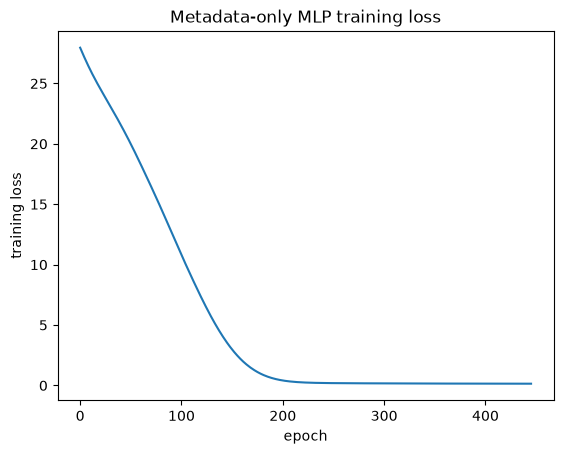

In [44]:
baseline_val_pred = np.full(len(y_val), y_fit.mean())
print("baseline validation MAE:", mean_absolute_error(y_val, baseline_val_pred))

mlp_meta = MLPRegressor(
    hidden_layer_sizes=(8,),
    activation="relu",
    learning_rate_init=0.001,
    max_iter=500,
    random_state=42,
).fit(X_meta_fit, y_fit)

# predict the validation ratings
y_meta_val_pred = mlp_meta.predict(X_meta_val)
print("metadata MLP validation MAE:", mean_absolute_error(y_val, y_meta_val_pred))

plt.figure()
plt.plot(mlp_meta.loss_curve_)
plt.xlabel("epoch")
plt.ylabel("training loss")
plt.title("Metadata-only MLP training loss")
plt.show()

### Split + Scale Metadata and Bayesian

In [46]:
# make separate yes/no column for each k value
k_dummies = pd.get_dummies(mlp_data["k"], prefix="k", dtype=int)

# columns from the Bayesian model
bayes_cols = ["posterior_mean", "posterior_std"]

X_bayes = pd.concat([mlp_data[metadata_cols], k_dummies, mlp_data[bayes_cols]], axis=1)

# keep only the training movies' rows
X_bayes_fit = X_bayes.loc[mlp_fit_rows].copy()

# keep only the validation movies' rows
X_bayes_val = X_bayes.loc[mlp_val_rows].copy()

# keep only the test movies' rows
X_bayes_test = X_bayes.loc[mlp_test_rows].copy()

bayes_numeric_cols = ["runtime", "release_year", "posterior_mean", "posterior_std"]
bayes_scaler = StandardScaler()

# scale the training columns
X_bayes_fit[bayes_numeric_cols] = bayes_scaler.fit_transform(X_bayes_fit[bayes_numeric_cols])

# scale validation and test 
X_bayes_val[bayes_numeric_cols] = bayes_scaler.transform(X_bayes_val[bayes_numeric_cols])
X_bayes_test[bayes_numeric_cols] = bayes_scaler.transform(X_bayes_test[bayes_numeric_cols])

print("fit:", X_bayes_fit.shape, "val:", X_bayes_val.shape, "test:", X_bayes_test.shape)
X_bayes_fit.head(7)

fit: (567, 20) val: (238, 20) test: (245, 20)


,runtime,release_year,genre_Adventure,genre_Animation,genre_Horror,mpaa_rating_G,mpaa_rating_Not Rated,mpaa_rating_PG,mpaa_rating_PG-13,mpaa_rating_R,mpaa_rating_TV-MA,k_-1,k_0,k_1,k_12,k_3,k_6,k_midpoint,posterior_mean,posterior_std
14,-0.608829,-0.678809,1,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,-0.052985,1.832642
15,-0.608829,-0.678809,1,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0.974929,-0.102068
16,-0.608829,-0.678809,1,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0.690774,-0.132185
17,-0.608829,-0.678809,1,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0.715728,-0.208780
18,-0.608829,-0.678809,1,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0.234771,-0.378732
19,-0.608829,-0.678809,1,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0.133038,-0.510216
20,-0.608829,-0.678809,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,-0.075991,-0.794283


### Train Metadata + Bayesian MLP

In [50]:
# build and train the MLP on metadata + Bayesian features
mlp_bayes = MLPRegressor(
    hidden_layer_sizes=(8,),
    activation="relu",
    learning_rate_init=0.001,
    max_iter=500,
    random_state=42,
).fit(X_bayes_fit, y_fit)

# predict ratings for the validation movies
y_bayes_val_pred = mlp_bayes.predict(X_bayes_val)

# compare average errors
print("baseline validation MAE:", mean_absolute_error(y_val, baseline_val_pred))
print("metadata MLP validation MAE:", mean_absolute_error(y_val, y_meta_val_pred))
print("metadata + Bayesian MLP validation MAE:", mean_absolute_error(y_val, y_bayes_val_pred))


baseline validation MAE: 0.6249818445896879
metadata MLP validation MAE: 0.5839694986329727
metadata + Bayesian MLP validation MAE: 0.4405648274776634


### Split and Scale Metadata + Bayesian + LSTM

In [51]:
lstm_mean = mlp_data["lstm_mean"].copy()

# fill no reviews with the average lstm mean
lstm_fill = lstm_mean[mlp_fit_rows & (mlp_data["k"] != "-1")].mean()
lstm_mean = lstm_mean.fillna(lstm_fill)

X_lstm = pd.concat([mlp_data[metadata_cols], k_dummies, mlp_data[bayes_cols], lstm_mean], axis=1)

# keep only wanted rows
X_lstm_fit = X_lstm.loc[mlp_fit_rows].copy()
X_lstm_val = X_lstm.loc[mlp_val_rows].copy()
X_lstm_test = X_lstm.loc[mlp_test_rows].copy()

lstm_numeric_cols = ["runtime", "release_year", "posterior_mean", "posterior_std", "lstm_mean"]
lstm_scaler = StandardScaler()

# scale training columns
X_lstm_fit[lstm_numeric_cols] = lstm_scaler.fit_transform(X_lstm_fit[lstm_numeric_cols])

# scale validation and test
X_lstm_val[lstm_numeric_cols] = lstm_scaler.transform(X_lstm_val[lstm_numeric_cols])
X_lstm_test[lstm_numeric_cols] = lstm_scaler.transform(X_lstm_test[lstm_numeric_cols])

print("fit:", X_lstm_fit.shape, "val:", X_lstm_val.shape, "test:", X_lstm_test.shape)
X_lstm_fit.head(7)


KeyError: 'lstm_mean'

### Train Metadata + Bayesian + LSTM mlp

In [53]:
mlp_bayes = MLPRegressor(
    hidden_layer_sizes=(8,),
    activation="relu",
    learning_rate_init=0.001,
    max_iter=500,
    random_state=42,
).fit(X_lstm_fit, y_fit)

# predict ratings for the validation movies
y_lstn_val_pred = mlp_bayes.predict(X_lstm_val)

# compare average errors
print("baseline validation MAE:", mean_absolute_error(y_val, baseline_val_pred))
print("metadata MLP validation MAE:", mean_absolute_error(y_val, y_meta_val_pred))
print("metadata + Bayesian MLP validation MAE:", mean_absolute_error(y_val, y_bayes_val_pred))
print("metadata + Bayesian + lstm MLP validation MAE:", mean_absolute_error(y_val, y_lstm_val_pred))

NameError: name 'X_lstm_fit' is not defined

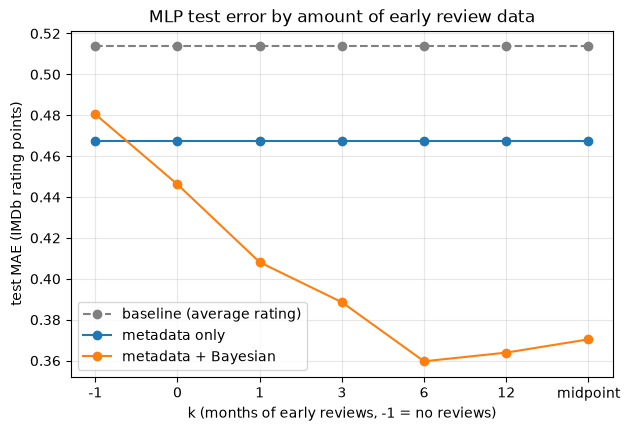

In [55]:
# predictions
baseline_test_pred = np.full(len(y_test), y_fit.mean())
y_meta_test_pred = mlp_meta.predict(X_meta_test)
y_bayes_test_pred = mlp_bayes.predict(X_bayes_test)
# y_lstm_test_pred = mlp_lstm.predict(X_lstm_test)

k_vals = ["-1", "0", "1", "3", "6", "12", "midpoint"]
k_test = mlp_data.loc[mlp_test_rows, "k"].to_numpy()

mae_by_k = []
for k in k_vals:
    is_k = k_test == k
    mae_by_k.append({
        "k": k,
        "baseline": mean_absolute_error(y_test[is_k], baseline_test_pred[is_k]),
        "metadata": mean_absolute_error(y_test[is_k], y_meta_test_pred[is_k]),
        "metadata + Bayesian": mean_absolute_error(y_test[is_k], y_bayes_test_pred[is_k]),
        # "metadata + Bayesian + LSTM": mean_absolute_error(y_test[is_k], y_lstm_test_pred[is_k]),
    })
mae_by_k = pd.DataFrame(mae_by_k)
    
plt.figure(figsize=(7, 4.5))

plt.plot(mae_by_k["k"], mae_by_k["baseline"], marker="o", linestyle="--", color="gray", label="baseline (average rating)")
plt.plot(mae_by_k["k"], mae_by_k["metadata"], marker="o", label="metadata only")
plt.plot(mae_by_k["k"], mae_by_k["metadata + Bayesian"], marker="o", label="metadata + Bayesian")
# plt.plot(mae_by_k["k"], mae_by_k["metadata + Bayesian + LSTM"], marker="o", label="metadata + Bayesian + LSTM")

plt.xlabel("k (months of early reviews, -1 = no reviews)")
plt.ylabel("test MAE (IMDb rating points)")
plt.title("MLP test error by amount of early review data")
plt.legend()
plt.grid(alpha=0.3)
plt.show()